# 🐾 CSE428 — Universal Multi-Model Inference & Evaluation Suite
### Interactive Plug-and-Play Demo & Systematic Benchmark for All Models (Raw Baseline to Bonus 1–5)

**Features:**
1. **Interactive Single-Image Evaluation:** Test any individual image on any specific model.
2. **Multi-Model Side-by-Side Visual Comparisons:** Compare Base U-Net, Attention U-Net, BiFPN-UNet, 3-Class Trimap U-Net, and ImageNet Pretrained Classifiers.
3. **Comprehensive Benchmark on External Test Images (`test images/`):** Systematic evaluation across all 5 test images (`Abyssinian_10.jpg`, `american_bulldog_131.jpg`, `american_pit_bull_terrier_14.jpg`, `basset_hound_148.jpg`, `beagle_84.jpg`).
4. **Publication-Ready Visual Overlays & Bar Charts:** Ground truth comparison, predicted mask overlays, IoU/Dice quantitative tables, and Top-5 breed confidence distributions.


In [1]:
import sys, os, time, warnings, pathlib
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import torchvision.transforms as T
import timm

from IPython.display import display, HTML

# Matplotlib styling for high-res clean presentation
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"CSE428 Evaluation Engine initialized on: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")


CSE428 Evaluation Engine initialized on: cuda (NVIDIA GeForce RTX 5050 Laptop GPU)


In [2]:
# ==============================================================================
# STEP 2: Dataset Discovery, Weight Resolution & Breed Dictionary
# ==============================================================================
def find_oxford_pet_paths():
    search_dirs = [
        'F:/pet-image-analysis-classification-detection/archive',
        'F:/428/archive',
        'F:/428',
        './archive',
        '../archive',
        '../../archive',
        './',
        '../..',
        '/kaggle/input/datasets/walidmahmooddczxcac/oxford-iiit-pet-2',
        '/kaggle/input/datasets/walidmahmood/oxford-iiit-pet',
        '/kaggle/input/oxford-iiit-pet',
    ]
    for d in search_dirs:
        for img_sub in ['images', 'images/images', 'oxford-iiit-pet/images']:
            for ann_sub in ['annotations/trimaps', 'annotations/annotations/trimaps', 'trimaps', 'annotations']:
                p_img = os.path.join(d, img_sub)
                p_ann = os.path.join(d, ann_sub)
                if os.path.isdir(p_img) and os.path.isdir(p_ann):
                    imgs = [f for f in os.listdir(p_img) if f.endswith(('.jpg', '.png', '.jpeg')) and not f.startswith('.')]
                    if len(imgs) > 100:
                        return os.path.abspath(p_img), os.path.abspath(p_ann)
    return None, None

IMG_DIR, ANN_DIR = find_oxford_pet_paths()
print(f"Image Directory:      {IMG_DIR}")
print(f"Annotation Directory: {ANN_DIR}")

# Build 37-Breed dictionary
raw_files = sorted([f for f in os.listdir(IMG_DIR) if f.endswith(('.jpg', '.png', '.jpeg')) and not f.startswith('.')]) if IMG_DIR else []
samples = []
for f in raw_files:
    base = os.path.splitext(f)[0]
    mask_name = f"{base}.png"
    mask_p = os.path.join(ANN_DIR, mask_name) if ANN_DIR else None
    if mask_p and os.path.exists(mask_p):
        breed = '_'.join(base.split('_')[:-1])
        samples.append({'file': f, 'base': base, 'breed': breed, 'img_path': os.path.join(IMG_DIR, f), 'mask_path': mask_p})

breeds = sorted(list(set(s['breed'] for s in samples))) if samples else [f'breed_{i}' for i in range(37)]
breed_to_idx = {b: i for i, b in enumerate(breeds)}
idx_to_breed = {i: b for b, i in breed_to_idx.items()}
print(f"Indexed {len(samples)} images across {len(breeds)} pet breeds.")

# Helper to resolve sample image path
def get_sample_image(filename='Abyssinian_10.jpg'):
    search_roots = [
        'F:/pet-image-analysis-classification-detection/test images',
        'F:/428/test images',
        'F:/428/archive/images',
        './test images',
        '../test images',
        '../../test images',
        './archive/images',
        '../archive/images',
        '../../archive/images',
        './images',
    ]
    for root in search_roots:
        p = os.path.join(root, filename)
        if os.path.exists(p): return os.path.abspath(p)
    if IMG_DIR and os.path.exists(os.path.join(IMG_DIR, filename)):
        return os.path.join(IMG_DIR, filename)
    return filename

# Helper to find model weights across all output directories
def find_weight_file(filename):
    search_roots = [
        'F:/pet-image-analysis-classification-detection/notebooks/final executed ones/raw_output',
        'F:/pet-image-analysis-classification-detection/notebooks/final executed ones/bonus123output',
        'F:/pet-image-analysis-classification-detection/notebooks/final executed ones/bonus4 output',
        'F:/pet-image-analysis-classification-detection/notebooks/final executed ones/bonus5 output/results',
        'F:/pet-image-analysis-classification-detection/notebooks/final executed ones/bonus5 output',
        './notebooks/final executed ones/raw_output',
        './notebooks/final executed ones/bonus123output',
        './notebooks/final executed ones/bonus4 output',
        './notebooks/final executed ones/bonus5 output/results',
        './raw_output',
        './bonus123output',
        './bonus4 output',
        './bonus5 output/results',
        './bonus5 output',
        '../raw_output',
        '../bonus123output',
        '../bonus4 output',
        '../bonus5 output/results',
        '../../notebooks/final executed ones/raw_output',
        '../../notebooks/final executed ones/bonus123output',
        '../../notebooks/final executed ones/bonus4 output',
        '../../notebooks/final executed ones/bonus5 output/results',
        'F:/428/final executed ones/final executed ones/raw_output',
        'F:/428/final executed ones/final executed ones/bonus123output',
        'F:/428/final executed ones/final executed ones/bonus4 output',
        'F:/428/final executed ones/final executed ones/bonus5 output/results',
        './'
    ]
    for root in search_roots:
        cand = os.path.join(root, filename)
        if os.path.exists(cand):
            return os.path.abspath(cand)
    return None


Image Directory:      F:\428\archive\images
Annotation Directory: F:\428\archive\annotations\trimaps


Indexed 7390 images across 37 pet breeds.


In [3]:
# ==============================================================================
# STEP 3: Unified Inference & Scoring Engine
# ==============================================================================
def preprocess_image(image_input, img_size=128):
    if isinstance(image_input, str):
        img = Image.open(image_input).convert('RGB')
    elif isinstance(image_input, np.ndarray):
        img = Image.fromarray(image_input).convert('RGB')
    else:
        img = image_input.convert('RGB')
    orig_w, orig_h = img.size
    img_resized = img.resize((img_size, img_size), Image.BILINEAR)
    img_t = TF.to_tensor(img_resized).unsqueeze(0).to(device)
    return img_t, img, (orig_w, orig_h)

def load_ground_truth_mask(mask_path_or_img_path, img_size=128):
    if not mask_path_or_img_path:
        return None
    mask_p = mask_path_or_img_path
    if not mask_p.endswith('.png') or not os.path.exists(mask_p):
        base = os.path.splitext(os.path.basename(mask_path_or_img_path))[0]
        search_dirs = [
            ANN_DIR,
            'F:/428/archive/annotations/trimaps',
            './archive/annotations/trimaps',
            '../archive/annotations/trimaps'
        ]
        found = False
        for sdir in search_dirs:
            if sdir and os.path.exists(sdir):
                cand = os.path.join(sdir, f'{base}.png')
                if os.path.exists(cand):
                    mask_p = cand
                    found = True
                    break
        if not found:
            return None
    if os.path.exists(mask_p):
        mask = Image.open(mask_p).resize((img_size, img_size), Image.NEAREST)
        return np.array(mask)
    return None

def calculate_metrics(pred_mask_bin, gt_mask_raw, task_type='binary'):
    if gt_mask_raw is None or pred_mask_bin is None:
        return {}
    if task_type == 'binary':
        # Oxford Pet Trimap: 1=Body, 2=Background, 3=Border
        # True pet binary mask = Foreground (1 & 3), Background (2 -> 0)
        gt_bin = np.where(gt_mask_raw == 2, 0, 1).astype(np.float32)
        p_bin = pred_mask_bin.astype(np.float32)
        inter = (p_bin * gt_bin).sum()
        union = p_bin.sum() + gt_bin.sum() - inter
        iou = (inter + 1e-6) / (union + 1e-6)
        dice = (2.0 * inter + 1e-6) / (p_bin.sum() + gt_bin.sum() + 1e-6)
        pix_acc = (p_bin == gt_bin).mean()
        return {'Dice Coefficient': dice, 'Mean IoU': iou, 'Pixel Accuracy': pix_acc}
    else:
        # 3-Class Trimap: 1->0 (Pet), 2->1 (BG), 3->2 (Border)
        gt_3c = gt_mask_raw - 1 if gt_mask_raw.min() >= 1 else gt_mask_raw
        p_3c = pred_mask_bin
        pix_acc = (p_3c == gt_3c).mean()
        ious = []
        for c in range(3):
            p_c = (p_3c == c).astype(np.float32)
            g_c = (gt_3c == c).astype(np.float32)
            inter = (p_c * g_c).sum()
            union = p_c.sum() + g_c.sum() - inter
            ious.append((inter + 1e-6) / (union + 1e-6) if union > 0 else 1.0)
        return {
            'Mean IoU (3-class)': np.mean(ious),
            'Pixel Accuracy': pix_acc,
            'Pet IoU': ious[0],
            'Background IoU': ious[1],
            'Border IoU': ious[2]
        }

def evaluate_and_display(model, image_path, model_title='Model', task_type='binary_multitask', mask_path=None, img_size=128):
    model.eval()
    img_t, pil_img, orig_dims = preprocess_image(image_path, img_size=img_size)
    gt_mask = load_ground_truth_mask(mask_path or image_path, img_size=img_size)
    
    t0 = time.time()
    with torch.no_grad():
        if task_type == 'classification_only':
            logits_cls = model(img_t)
            logits_seg = None
        else:
            logits_seg, logits_cls = model(img_t)
    dt_ms = (time.time() - t0) * 1000.0

    pred_mask = None
    if logits_seg is not None:
        if task_type in ['binary_multitask', 'binary_seg_only']:
            probs_seg = torch.sigmoid(logits_seg).squeeze().cpu().numpy()
            pred_mask = (probs_seg > 0.5).astype(np.uint8)
        else:
            probs_seg = torch.softmax(logits_seg, dim=1).squeeze().cpu().numpy()
            pred_mask = np.argmax(probs_seg, axis=0)

    top5_probs, top5_breeds = [], []
    pred_breed = 'N/A'
    conf_pct = 0.0
    if logits_cls is not None:
        probs_cls = torch.softmax(logits_cls, dim=1).squeeze().cpu().numpy()
        top5_idx = np.argsort(probs_cls)[::-1][:5]
        top5_probs = probs_cls[top5_idx] * 100.0
        top5_breeds = [idx_to_breed.get(i, f'Class {i}') for i in top5_idx]
        pred_breed = top5_breeds[0]
        conf_pct = top5_probs[0]

    metrics = calculate_metrics(pred_mask, gt_mask, task_type='3class' if '3class' in task_type else 'binary')

    num_cols = 4 if gt_mask is not None else 3
    if task_type == 'classification_only':
        num_cols = 2

    fig = plt.figure(figsize=(5.5 * num_cols, 4.5))

    # Subplot 1: Input Photo
    ax1 = fig.add_subplot(1, num_cols, 1)
    ax1.imshow(pil_img)
    base_name = os.path.splitext(os.path.basename(image_path))[0]
    inferred_breed = '_'.join(base_name.split('_')[:-1])
    true_breed_str = f"True: {inferred_breed}\n" if inferred_breed in breed_to_idx else ""
    ax1.set_title(f"Input Image\n{true_breed_str}Pred: {pred_breed} ({conf_pct:.1f}%)", fontsize=11, fontweight='bold')
    ax1.axis('off')

    col_idx = 2
    # Subplot 2: Ground Truth Mask
    if gt_mask is not None and task_type != 'classification_only':
        ax_gt = fig.add_subplot(1, num_cols, col_idx)
        if '3class' in task_type:
            ax_gt.imshow(gt_mask, cmap='viridis')
            ax_gt.set_title('Ground Truth Trimap\n(1=Pet, 2=BG, 3=Border)', fontsize=11, fontweight='bold')
        else:
            gt_bin_viz = np.where(gt_mask == 2, 0, 1)
            ax_gt.imshow(gt_bin_viz, cmap='gray')
            ax_gt.set_title('Ground Truth Mask\n(White=Pet Silhouette)', fontsize=11, fontweight='bold')
        ax_gt.axis('off')
        col_idx += 1

    # Subplot 3: Predicted Overlay
    if pred_mask is not None:
        ax_pred = fig.add_subplot(1, num_cols, col_idx)
        img_np = np.array(pil_img.resize((img_size, img_size))) / 255.0
        if '3class' in task_type:
            overlay = img_np.copy()
            overlay[pred_mask == 0] = overlay[pred_mask == 0] * 0.5 + np.array([0, 0.8, 0]) * 0.5
            overlay[pred_mask == 2] = overlay[pred_mask == 2] * 0.4 + np.array([0.9, 0.1, 0.1]) * 0.6
            ax_pred.imshow(overlay)
            score_str = f"mIoU: {metrics.get('Mean IoU (3-class)', 0):.3f} | PixAcc: {metrics.get('Pixel Accuracy', 0)*100:.1f}%" if metrics else ''
            ax_pred.set_title(f"3-Class Predicted Overlay\n{score_str}", fontsize=11, fontweight='bold')
        else:
            overlay = img_np.copy()
            overlay[pred_mask == 1] = overlay[pred_mask == 1] * 0.5 + np.array([0.1, 0.85, 0.2]) * 0.5
            ax_pred.imshow(overlay)
            score_str = f"Dice: {metrics.get('Dice Coefficient', 0):.3f} | IoU: {metrics.get('Mean IoU', 0):.3f}" if metrics else ''
            ax_pred.set_title(f"Predicted Pet Mask Overlay\n{score_str}", fontsize=11, fontweight='bold')
        ax_pred.axis('off')
        col_idx += 1

    # Subplot 4: Top-5 Probabilities
    if len(top5_probs) > 0:
        ax_bar = fig.add_subplot(1, num_cols, col_idx)
        y_pos = np.arange(len(top5_breeds))[::-1]
        colors = ['#2ca02c' if i == 0 else '#1f77b4' for i in range(len(top5_breeds))]
        bars = ax_bar.barh(y_pos, top5_probs, color=colors, edgecolor='black', linewidth=0.6, height=0.6)
        ax_bar.set_yticks(y_pos)
        ax_bar.set_yticklabels(top5_breeds, fontsize=9.5, fontweight='bold')
        ax_bar.set_xlim(0, 105)
        ax_bar.set_xlabel('Confidence (%)', fontsize=10, fontweight='bold')
        ax_bar.set_title('Top-5 Breed Probabilities', fontsize=11, fontweight='bold')
        for bar, p_val in zip(bars, top5_probs):
            ax_bar.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height()/2, f'{p_val:.1f}%', va='center', fontsize=9, fontweight='bold')

    fig.suptitle(f"Evaluation: {model_title} | Latency: {dt_ms:.1f} ms | Device: {device}", fontsize=13, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.show()

    if metrics:
        df_m = pd.DataFrame([{'Metric': k, 'Score': f"{v:.4f}" if isinstance(v, float) else v} for k, v in metrics.items()])
        df_m.loc[len(df_m)] = {'Metric': 'Inference Latency', 'Score': f"{dt_ms:.2f} ms"}
        df_m.loc[len(df_m)] = {'Metric': 'Top-1 Classification Confidence', 'Score': f"{conf_pct:.2f}%"}
        print(f"\nQUANTITATIVE SCORES — {model_title.upper()}")
        try:
            display(df_m.style.hide(axis='index'))
        except Exception:
            print(df_m.to_string(index=False))


In [4]:
# ==============================================================================
# STEP 4: Neural Architecture Compilations
# ==============================================================================
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.block(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1, bias=False), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1, bias=False), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1, bias=False), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
    def forward(self, g, x):
        return x * self.psi(self.relu(self.W_g(g) + self.W_x(x)))

class DeepMultiTaskUNet(nn.Module):
    # Deep 4-Stage MultiTask U-Net (Used in Raw Baseline: 3.47M params)
    def __init__(self, in_ch=3, num_classes_breed=37, seg_classes=1, use_attention=False):
        super().__init__()
        self.use_attention = use_attention
        self.enc1 = ConvBlock(in_ch, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)
        self.bottleneck = ConvBlock(256, 256)
        self.pool = nn.MaxPool2d(2)
        self.class_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(256, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes_breed)
        )
        self.up4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.att4 = AttentionGate(128, 256, 64) if use_attention else None
        self.dec4 = ConvBlock(128 + 256, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.att3 = AttentionGate(64, 128, 32) if use_attention else None
        self.dec3 = ConvBlock(64 + 128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.att2 = AttentionGate(32, 64, 16) if use_attention else None
        self.dec2 = ConvBlock(32 + 64, 32)
        self.up1 = nn.ConvTranspose2d(32, 32, 2, stride=2)
        self.att1 = AttentionGate(32, 32, 16) if use_attention else None
        self.dec1 = ConvBlock(32 + 32, 32)
        self.seg_head = nn.Conv2d(32, seg_classes, 1)

    def forward(self, x):
        c1 = self.enc1(x)
        c2 = self.enc2(self.pool(c1))
        c3 = self.enc3(self.pool(c2))
        c4 = self.enc4(self.pool(c3))
        b  = self.bottleneck(self.pool(c4))
        logits_cls = self.class_head(b)
        u4 = self.up4(b); d4 = self.dec4(torch.cat([u4, self.att4(u4, c4) if self.use_attention else c4], dim=1))
        u3 = self.up3(d4); d3 = self.dec3(torch.cat([u3, self.att3(u3, c3) if self.use_attention else c3], dim=1))
        u2 = self.up2(d3); d2 = self.dec2(torch.cat([u2, self.att2(u2, c2) if self.use_attention else c2], dim=1))
        u1 = self.up1(d2); d1 = self.dec1(torch.cat([u1, self.att1(u1, c1) if self.use_attention else c1], dim=1))
        return self.seg_head(d1), logits_cls

class StandardMultiTaskUNet(nn.Module):
    # Standard 2-Stage MultiTask U-Net (Used in Bonus 1, 2, 3, 1.92M params)
    def __init__(self, in_ch=3, num_classes_breed=37, seg_classes=1, use_attention=False):
        super().__init__()
        self.use_attention = use_attention
        self.enc1 = ConvBlock(in_ch, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(128, 256)
        self.class_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes_breed)
        )
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.att1 = AttentionGate(128, 128, 64) if use_attention else None
        self.dec1 = ConvBlock(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.att2 = AttentionGate(64, 64, 32) if use_attention else None
        self.dec2 = ConvBlock(128, 64)
        self.seg_head = nn.Conv2d(64, seg_classes, 1)

    def forward(self, x):
        c1 = self.enc1(x)
        p1 = self.pool1(c1)
        c2 = self.enc2(p1)
        p2 = self.pool2(c2)
        b = self.bottleneck(p2)
        logits_cls = self.class_head(b)
        u1 = self.up1(b)
        u1 = torch.cat([u1, self.att1(u1, c2) if self.use_attention else c2], dim=1)
        d1 = self.dec1(u1)
        u2 = self.up2(d1)
        u2 = torch.cat([u2, self.att2(u2, c1) if self.use_attention else c1], dim=1)
        d2 = self.dec2(u2)
        return self.seg_head(d2), logits_cls

class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, padding=1, bias=False):
        super().__init__()
        self.depthwise = nn.Conv2d(in_ch, in_ch, kernel_size, padding=padding, groups=in_ch, bias=bias)
        self.pointwise = nn.Conv2d(in_ch, out_ch, 1, bias=bias)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.act(self.bn(self.pointwise(self.depthwise(x))))

class FastNormalizedFusion(nn.Module):
    def __init__(self, num_inputs, eps=1e-4):
        super().__init__()
        self.weights = nn.Parameter(torch.ones(num_inputs, dtype=torch.float32))
        self.eps = eps
    def forward(self, inputs):
        w = F.relu(self.weights)
        w_sum = w.sum() + self.eps
        fused = sum(w_i * inp for w_i, inp in zip(w, inputs))
        return fused / w_sum

class BiFPNLayer(nn.Module):
    def __init__(self, fpn_channels=64):
        super().__init__()
        ch = fpn_channels
        self.td_fuse_p2 = FastNormalizedFusion(num_inputs=2)
        self.td_conv_p2 = DepthwiseSeparableConv(ch, ch)
        self.td_fuse_p1 = FastNormalizedFusion(num_inputs=2)
        self.td_conv_p1 = DepthwiseSeparableConv(ch, ch)
        self.bu_fuse_p2 = FastNormalizedFusion(num_inputs=3)
        self.bu_conv_p2 = DepthwiseSeparableConv(ch, ch)
        self.bu_fuse_p3 = FastNormalizedFusion(num_inputs=2)
        self.bu_conv_p3 = DepthwiseSeparableConv(ch, ch)
    def forward(self, p1, p2, p3):
        p3_up = F.interpolate(p3, size=p2.shape[2:], mode='nearest')
        p2_td = self.td_conv_p2(self.td_fuse_p2([p2, p3_up]))
        p2_td_up = F.interpolate(p2_td, size=p1.shape[2:], mode='nearest')
        p1_td = self.td_conv_p1(self.td_fuse_p1([p1, p2_td_up]))
        p1_td_down = F.max_pool2d(p1_td, kernel_size=2)
        p2_bu = self.bu_conv_p2(self.bu_fuse_p2([p2, p2_td, p1_td_down]))
        p2_bu_down = F.max_pool2d(p2_bu, kernel_size=2)
        p3_bu = self.bu_conv_p3(self.bu_fuse_p3([p3, p2_bu_down]))
        return p1_td, p2_bu, p3_bu

class MultiTaskBiFPNUNet(nn.Module):
    # Bonus 5: EfficientDet BiFPN Decoder MultiTask U-Net (1.26M params)
    def __init__(self, in_ch=3, num_classes_breed=37, seg_classes=1, fpn_channels=64, num_bifpn_layers=2):
        super().__init__()
        self.fpn_channels = fpn_channels
        self.enc1 = ConvBlock(in_ch, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(128, 256)
        self.class_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes_breed)
        )
        self.proj_p1 = nn.Conv2d(64, fpn_channels, 1)
        self.proj_p2 = nn.Conv2d(128, fpn_channels, 1)
        self.proj_p3 = nn.Conv2d(256, fpn_channels, 1)
        self.bifpn_layers = nn.ModuleList([BiFPNLayer(fpn_channels) for _ in range(num_bifpn_layers)])
        self.seg_head = nn.Sequential(
            DepthwiseSeparableConv(fpn_channels, fpn_channels),
            nn.Conv2d(fpn_channels, seg_classes, 1)
        )
    def forward(self, x):
        c1 = self.enc1(x)
        p1 = self.pool1(c1)
        c2 = self.enc2(p1)
        p2 = self.pool2(c2)
        b = self.bottleneck(p2)
        logits_cls = self.class_head(b)
        fp1 = self.proj_p1(c1)
        fp2 = self.proj_p2(c2)
        fp3 = self.proj_p3(b)
        for bifpn in self.bifpn_layers:
            fp1, fp2, fp3 = bifpn(fp1, fp2, fp3)
        logits_seg = self.seg_head(fp1)
        return logits_seg, logits_cls

def load_bonus1_model(arch_name, mode='pretrained'):
    arch_map = {
        'DenseNet121': 'densenet121',
        'EfficientNetB0': 'efficientnet_b0',
        'MobileNetV2': 'mobilenetv2_100'
    }
    model_id = arch_map.get(arch_name, arch_name)
    model = timm.create_model(model_id, pretrained=False, num_classes=37).to(device)
    filename = f"bonus1_{arch_name}_{mode}.pth"
    weights_path = find_weight_file(filename)
    if weights_path:
        model.load_state_dict(torch.load(weights_path, map_location=device))
        print(f"Loaded {arch_name} ({mode}) from: {weights_path}")
    else:
        print(f"Weights for {arch_name} ({mode}) [{filename}] not found!")
    model.eval()
    return model

print("All Neural Architectures (Raw Baseline, Bonus 1, 2, 3, 5) compiled and ready!")


All Neural Architectures (Raw Baseline, Bonus 1, 2, 3, 5) compiled and ready!


### 🔬 Model 1: Raw Attention U-Net (Deep 3.47M Params)

Loaded weights from: F:\428\final executed ones\final executed ones\raw_output\best_att_binary.pth


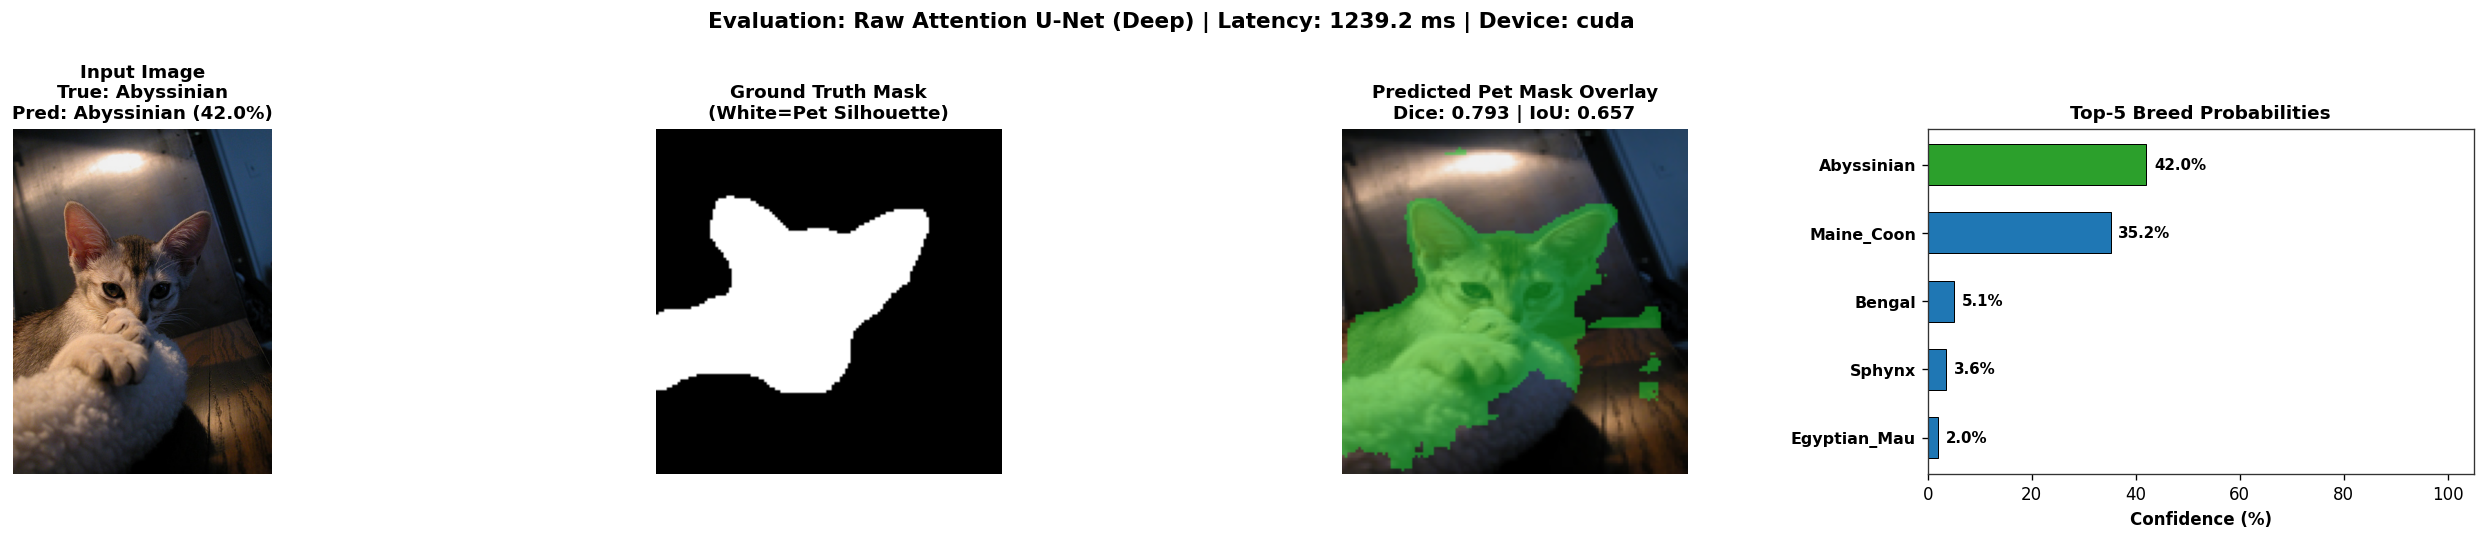


QUANTITATIVE SCORES — RAW ATTENTION U-NET (DEEP)


Metric,Score
Dice Coefficient,0.7930
Mean IoU,0.6570
Pixel Accuracy,0.8644
Inference Latency,1239.21 ms
Top-1 Classification Confidence,42.05%


In [5]:
# --- MODEL 1: RAW ATTENTION U-NET ---
IMAGE_PATH = get_sample_image('Abyssinian_10.jpg')

raw_att_model = DeepMultiTaskUNet(use_attention=True, seg_classes=1).to(device)
weights_path = find_weight_file('best_att_binary.pth')
if weights_path:
    raw_att_model.load_state_dict(torch.load(weights_path, map_location=device))
    print(f"Loaded weights from: {weights_path}")
evaluate_and_display(raw_att_model, IMAGE_PATH, model_title='Raw Attention U-Net (Deep)', task_type='binary_multitask')


### 🔬 Model 2: Raw Base U-Net (Deep 3.44M Params)

Loaded weights from: F:\428\final executed ones\final executed ones\raw_output\best_base_binary.pth


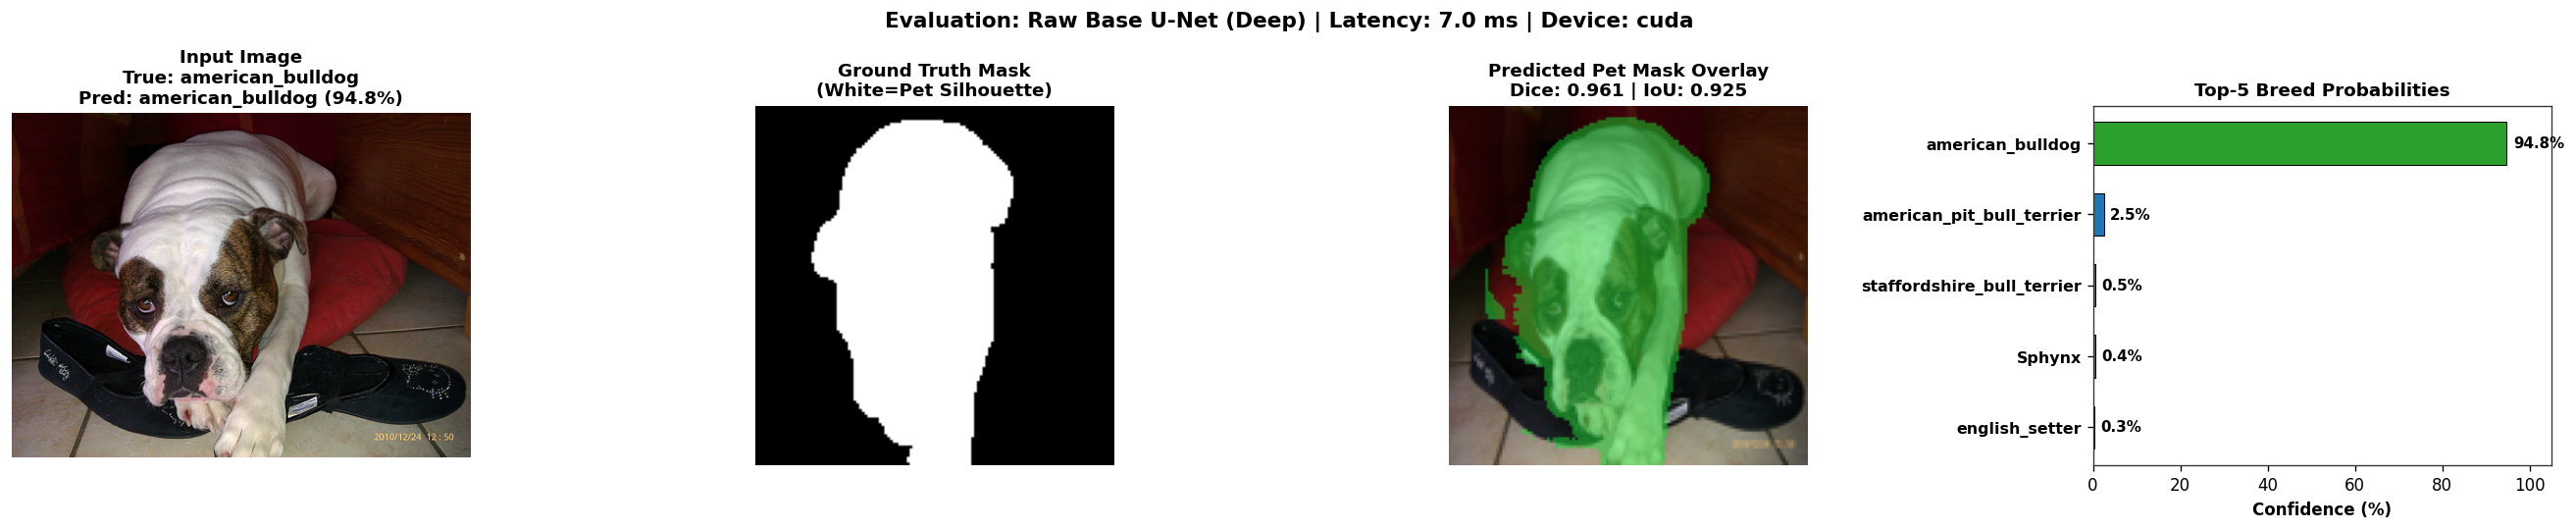


QUANTITATIVE SCORES — RAW BASE U-NET (DEEP)


Metric,Score
Dice Coefficient,0.9611
Mean IoU,0.9250
Pixel Accuracy,0.9700
Inference Latency,7.00 ms
Top-1 Classification Confidence,94.76%


In [6]:
# --- MODEL 2: RAW BASE U-NET ---
IMAGE_PATH = get_sample_image('american_bulldog_131.jpg')

raw_base_model = DeepMultiTaskUNet(use_attention=False, seg_classes=1).to(device)
weights_path = find_weight_file('best_base_binary.pth')
if weights_path:
    raw_base_model.load_state_dict(torch.load(weights_path, map_location=device))
    print(f"Loaded weights from: {weights_path}")
evaluate_and_display(raw_base_model, IMAGE_PATH, model_title='Raw Base U-Net (Deep)', task_type='binary_multitask')


### 🔬 Model 3: Bonus 5 — EfficientDet BiFPN-UNet (1.26M Params)

Loaded weights from: F:\428\final executed ones\final executed ones\bonus5 output\results\bonus5_bifpn_unet.pth


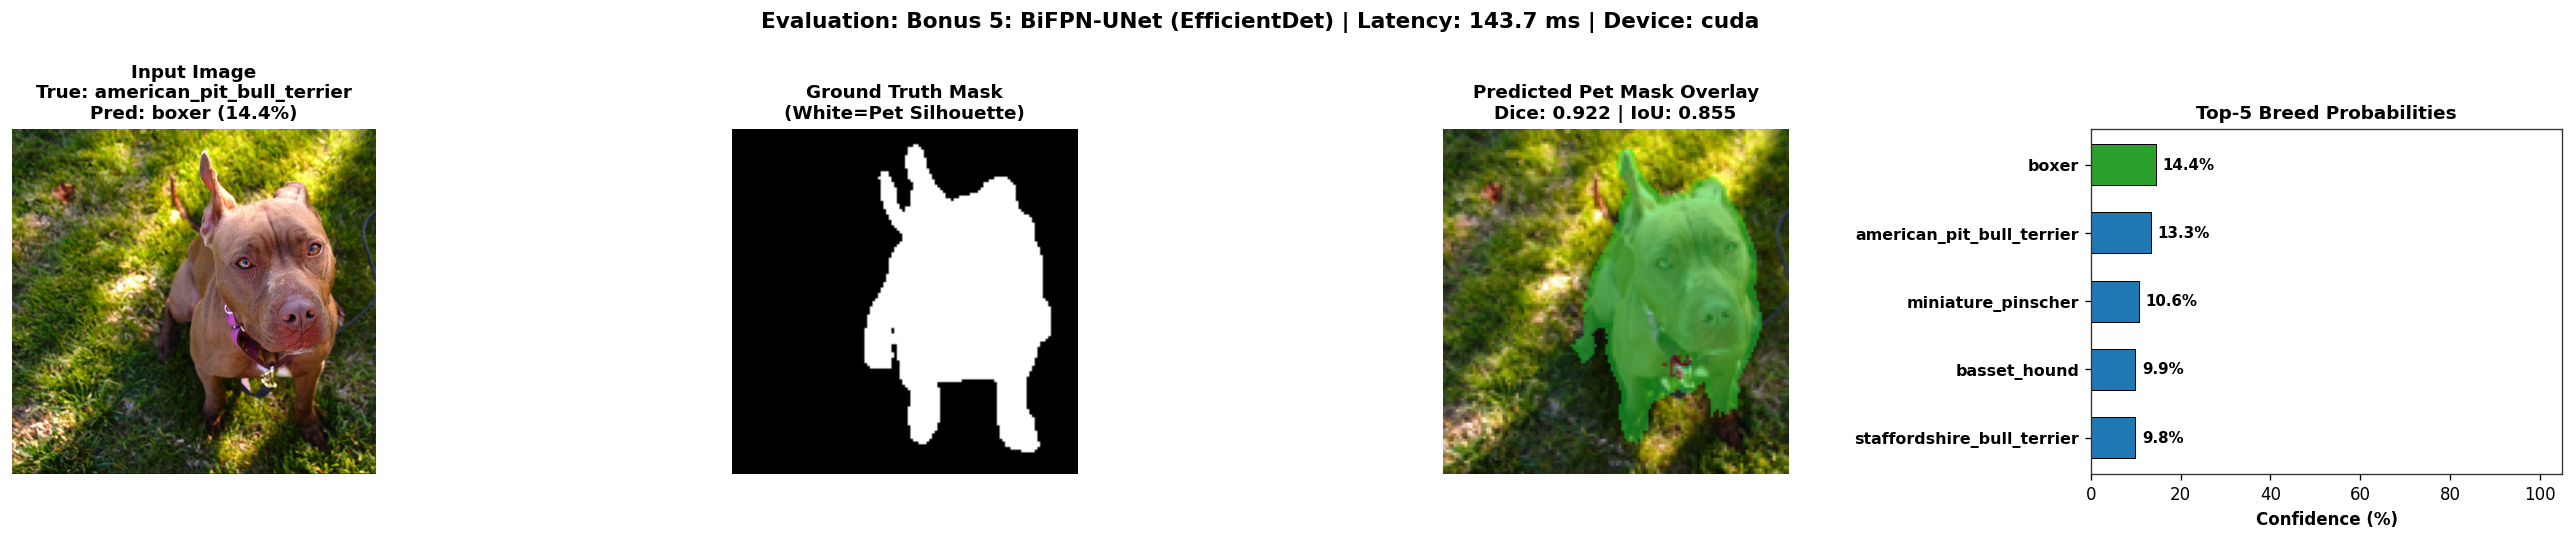


QUANTITATIVE SCORES — BONUS 5: BIFPN-UNET (EFFICIENTDET)


Metric,Score
Dice Coefficient,0.9217
Mean IoU,0.8548
Pixel Accuracy,0.9558
Inference Latency,143.65 ms
Top-1 Classification Confidence,14.38%


In [7]:
# --- MODEL 3: BONUS 5 (BiFPN-UNet) ---
IMAGE_PATH = get_sample_image('american_pit_bull_terrier_14.jpg')

bifpn_model = MultiTaskBiFPNUNet(num_classes_breed=37, seg_classes=1, num_bifpn_layers=2).to(device)
weights_path = find_weight_file('bonus5_bifpn_unet.pth')
if weights_path:
    bifpn_model.load_state_dict(torch.load(weights_path, map_location=device))
    print(f"Loaded weights from: {weights_path}")
evaluate_and_display(bifpn_model, IMAGE_PATH, model_title='Bonus 5: BiFPN-UNet (EfficientDet)', task_type='binary_multitask')


### 🔬 Model 4: Bonus 3 — 3-Class Trimap Attention U-Net

Loaded weights from: F:\428\final executed ones\final executed ones\bonus123output\best_att_3.pth


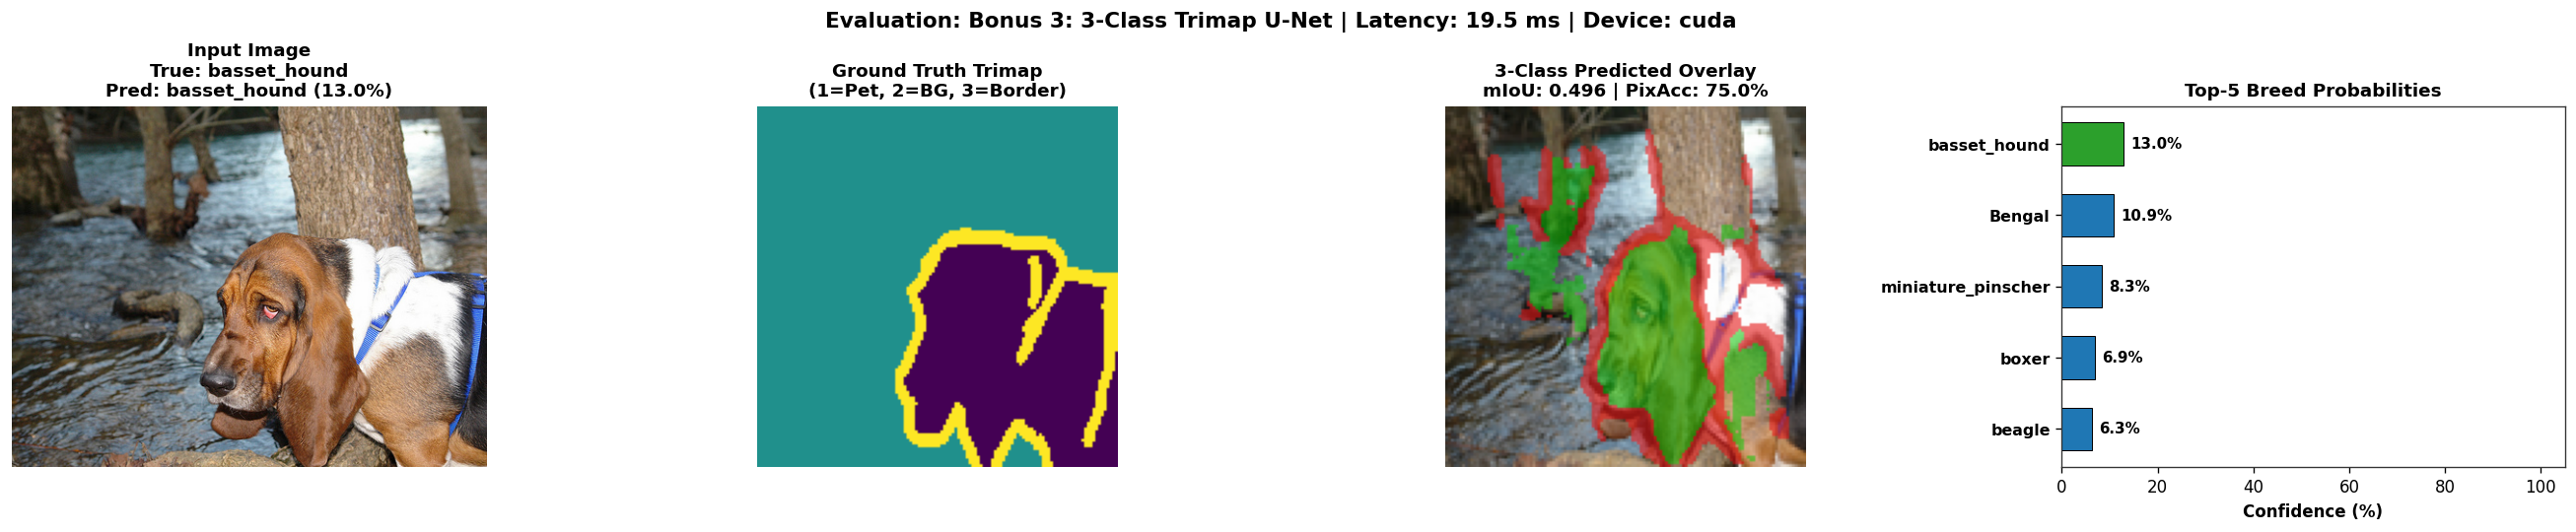


QUANTITATIVE SCORES — BONUS 3: 3-CLASS TRIMAP U-NET


Metric,Score
Mean IoU (3-class),0.4960
Pixel Accuracy,0.7498
Pet IoU,0.4778
Background IoU,0.7316
Border IoU,0.2787
Inference Latency,19.51 ms
Top-1 Classification Confidence,12.97%


In [8]:
# --- MODEL 4: BONUS 3 (3-CLASS TRIMAP U-NET) ---
IMAGE_PATH = get_sample_image('basset_hound_148.jpg')

trimap_model = StandardMultiTaskUNet(in_ch=3, num_classes_breed=37, seg_classes=3, use_attention=True).to(device)
weights_path = find_weight_file('best_att_3.pth')
if weights_path:
    trimap_model.load_state_dict(torch.load(weights_path, map_location=device))
    print(f"Loaded weights from: {weights_path}")
evaluate_and_display(trimap_model, IMAGE_PATH, model_title='Bonus 3: 3-Class Trimap U-Net', task_type='3class_multitask')


### 🔬 Model 5: Bonus 1 — Pretrained ImageNet Classifiers (DenseNet121, EfficientNet-B0, MobileNetV2)

Loaded EfficientNetB0 (pretrained) from: F:\428\final executed ones\final executed ones\bonus123output\bonus1_EfficientNetB0_pretrained.pth


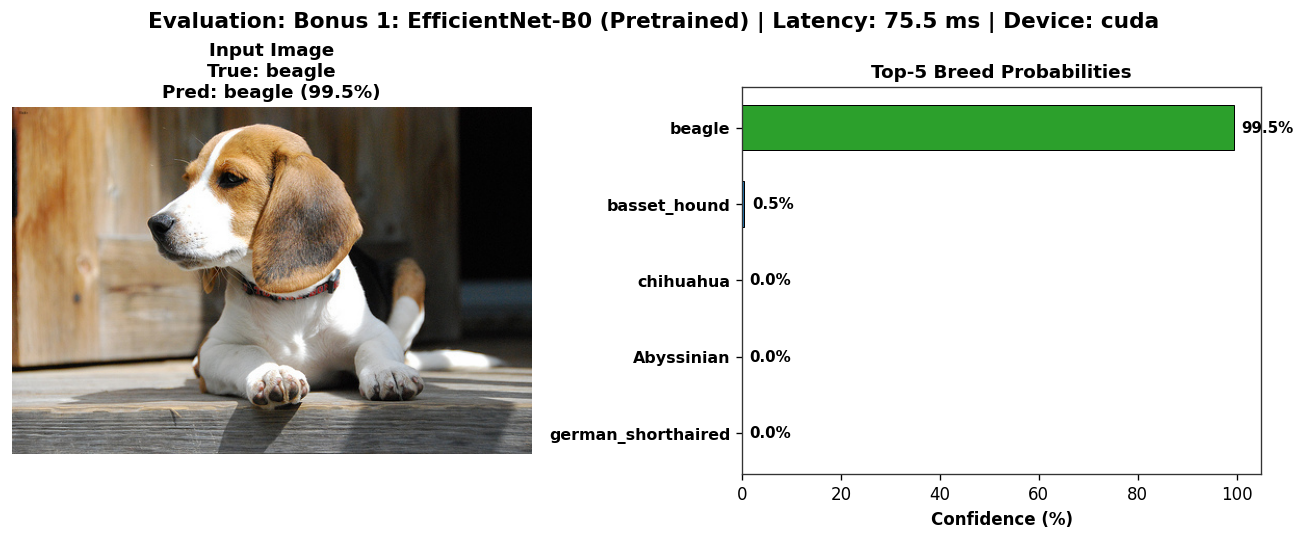

In [9]:
# --- MODEL 5: EfficientNet-B0 (PRETRAINED) ---
IMAGE_PATH = get_sample_image('beagle_84.jpg')
effnet_pre = load_bonus1_model('EfficientNetB0', mode='pretrained')
evaluate_and_display(effnet_pre, IMAGE_PATH, model_title='Bonus 1: EfficientNet-B0 (Pretrained)', task_type='classification_only')


---

In [10]:
# --- BONUS 1 ALL-6-MODEL CLASSIFIER COMPARATOR ---
IMAGE_PATH = get_sample_image('american_pit_bull_terrier_14.jpg')

models_bonus1 = {
    'DenseNet121 (Pretrained)': load_bonus1_model('DenseNet121', 'pretrained'),
    'DenseNet121 (Scratch)': load_bonus1_model('DenseNet121', 'scratch'),
    'EfficientNetB0 (Pretrained)': load_bonus1_model('EfficientNetB0', 'pretrained'),
    'EfficientNetB0 (Scratch)': load_bonus1_model('EfficientNetB0', 'scratch'),
    'MobileNetV2 (Pretrained)': load_bonus1_model('MobileNetV2', 'pretrained'),
    'MobileNetV2 (Scratch)': load_bonus1_model('MobileNetV2', 'scratch'),
}

img_t, pil_img, _ = preprocess_image(IMAGE_PATH, img_size=128)
base_name = os.path.splitext(os.path.basename(IMAGE_PATH))[0]
true_b = '_'.join(base_name.split('_')[:-1])

b1_rows = []
for name, m in models_bonus1.items():
    t0 = time.time()
    with torch.no_grad():
        logits = m(img_t)
    dt = (time.time() - t0) * 1000
    probs = torch.softmax(logits, dim=1).squeeze().cpu().numpy()
    pred_idx = np.argmax(probs)
    pred_b = idx_to_breed.get(pred_idx, 'N/A')
    conf = probs[pred_idx] * 100
    b1_rows.append({
        'Backbone Architecture': name,
        'Predicted Breed': pred_b,
        'Confidence': f"{conf:.2f}%",
        'Correct?': '✅ Correct' if pred_b.lower() == true_b.lower() else '❌ Misclassified',
        'Latency': f"{dt:.1f} ms"
    })

print(f"\nBONUS 1 CLASSIFIER BACKBONE COMPARISON ON: '{os.path.basename(IMAGE_PATH)}' (True: {true_b})")
df_b1 = pd.DataFrame(b1_rows)
display(df_b1.style.hide(axis='index'))


Loaded DenseNet121 (pretrained) from: F:\428\final executed ones\final executed ones\bonus123output\bonus1_DenseNet121_pretrained.pth


Loaded DenseNet121 (scratch) from: F:\428\final executed ones\final executed ones\bonus123output\bonus1_DenseNet121_scratch.pth


Loaded EfficientNetB0 (pretrained) from: F:\428\final executed ones\final executed ones\bonus123output\bonus1_EfficientNetB0_pretrained.pth


Loaded EfficientNetB0 (scratch) from: F:\428\final executed ones\final executed ones\bonus123output\bonus1_EfficientNetB0_scratch.pth
Loaded MobileNetV2 (pretrained) from: F:\428\final executed ones\final executed ones\bonus123output\bonus1_MobileNetV2_pretrained.pth


Loaded MobileNetV2 (scratch) from: F:\428\final executed ones\final executed ones\bonus123output\bonus1_MobileNetV2_scratch.pth



BONUS 1 CLASSIFIER BACKBONE COMPARISON ON: 'american_pit_bull_terrier_14.jpg' (True: american_pit_bull_terrier)


Backbone Architecture,Predicted Breed,Confidence,Correct?,Latency
DenseNet121 (Pretrained),american_pit_bull_terrier,96.24%,✅ Correct,108.7 ms
DenseNet121 (Scratch),yorkshire_terrier,18.61%,❌ Misclassified,51.0 ms
EfficientNetB0 (Pretrained),american_pit_bull_terrier,98.69%,✅ Correct,15.0 ms
EfficientNetB0 (Scratch),yorkshire_terrier,21.47%,❌ Misclassified,13.5 ms
MobileNetV2 (Pretrained),american_pit_bull_terrier,99.15%,✅ Correct,31.7 ms
MobileNetV2 (Scratch),yorkshire_terrier,12.38%,❌ Misclassified,8.6 ms


# ==============================================================================
# 🌟 SECTION 5: SYSTEMATIC BENCHMARK ACROSS ALL 5 TEST IMAGES (`test images/`)
# ==============================================================================
We now run our multi-model comparative suite on all 5 images found in `f:/428/test images/`:
1. `Abyssinian_10.jpg` (Cat: Abyssinian)
2. `american_bulldog_131.jpg` (Dog: American Bulldog)
3. `american_pit_bull_terrier_14.jpg` (Dog: American Pit Bull Terrier)
4. `basset_hound_148.jpg` (Dog: Basset Hound)
5. `beagle_84.jpg` (Dog: Beagle)


In [11]:
# Load the core multi-task models for comparison
models_to_compare = {
    'Raw Attention U-Net': (DeepMultiTaskUNet(use_attention=True, seg_classes=1).to(device), 'best_att_binary.pth', 'binary'),
    'Raw Base U-Net': (DeepMultiTaskUNet(use_attention=False, seg_classes=1).to(device), 'best_base_binary.pth', 'binary'),
    'Bonus 5: BiFPN-UNet': (MultiTaskBiFPNUNet(num_classes_breed=37, seg_classes=1).to(device), 'bonus5_bifpn_unet.pth', 'binary'),
    'Bonus 3: 3-Class Trimap': (StandardMultiTaskUNet(seg_classes=3, use_attention=True).to(device), 'best_att_3.pth', '3class')
}

for name, (m, wf, _) in models_to_compare.items():
    p = find_weight_file(wf)
    if p:
        m.load_state_dict(torch.load(p, map_location=device))
        print(f"Ready: {name:25s} (loaded from {p})")
    m.eval()

# Also load EfficientNet-B0 pretrained for classifier comparison
effnet_model = load_bonus1_model('EfficientNetB0', 'pretrained')

test_images_cand = [
    'F:/pet-image-analysis-classification-detection/test images',
    './test images',
    '../test images',
    '../../test images',
    'F:/428/test images'
]
test_images_dir = next((p for p in test_images_cand if os.path.exists(p)), './test images')
test_image_files = sorted([f for f in os.listdir(test_images_dir) if f.endswith(('.jpg', '.png')) and not f.startswith('.')])
print(f"\nFound {len(test_image_files)} test images in: {test_images_dir}")


Ready: Raw Attention U-Net       (loaded from F:\428\final executed ones\final executed ones\raw_output\best_att_binary.pth)
Ready: Raw Base U-Net            (loaded from F:\428\final executed ones\final executed ones\raw_output\best_base_binary.pth)


Ready: Bonus 5: BiFPN-UNet       (loaded from F:\428\final executed ones\final executed ones\bonus5 output\results\bonus5_bifpn_unet.pth)
Ready: Bonus 3: 3-Class Trimap   (loaded from F:\428\final executed ones\final executed ones\bonus123output\best_att_3.pth)


Loaded EfficientNetB0 (pretrained) from: F:\428\final executed ones\final executed ones\bonus123output\bonus1_EfficientNetB0_pretrained.pth

Found 5 test images in: F:/428/test images


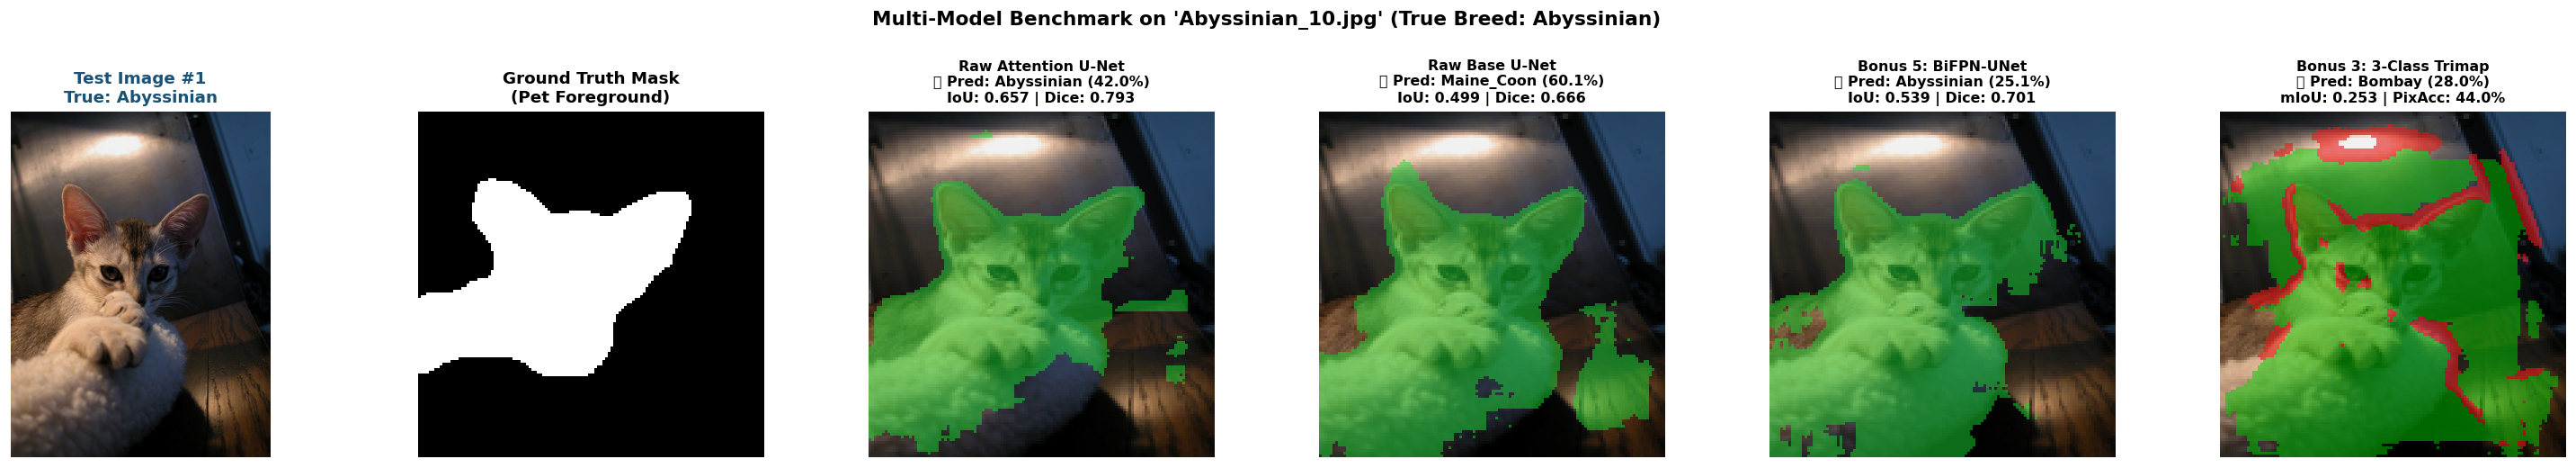

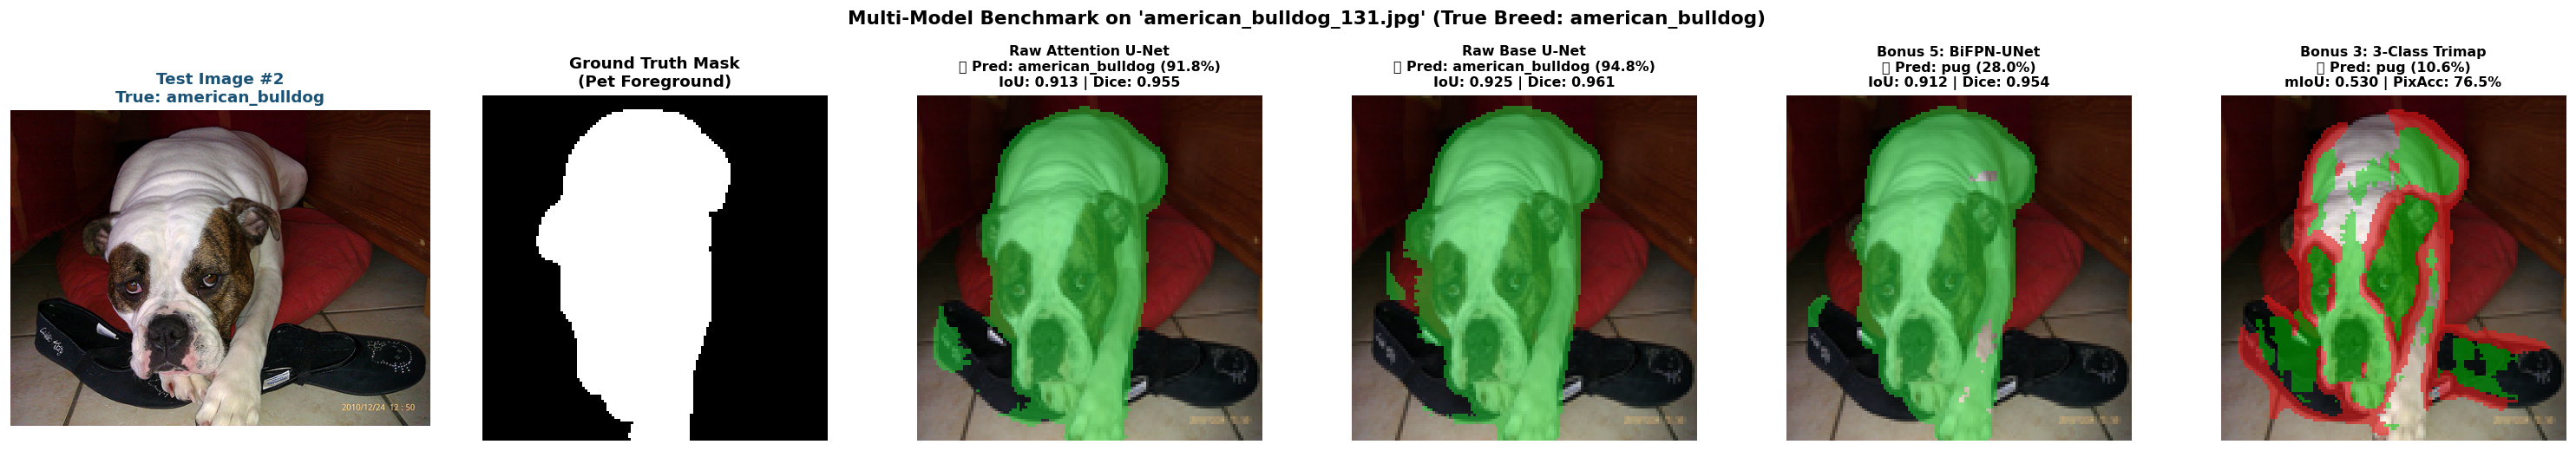

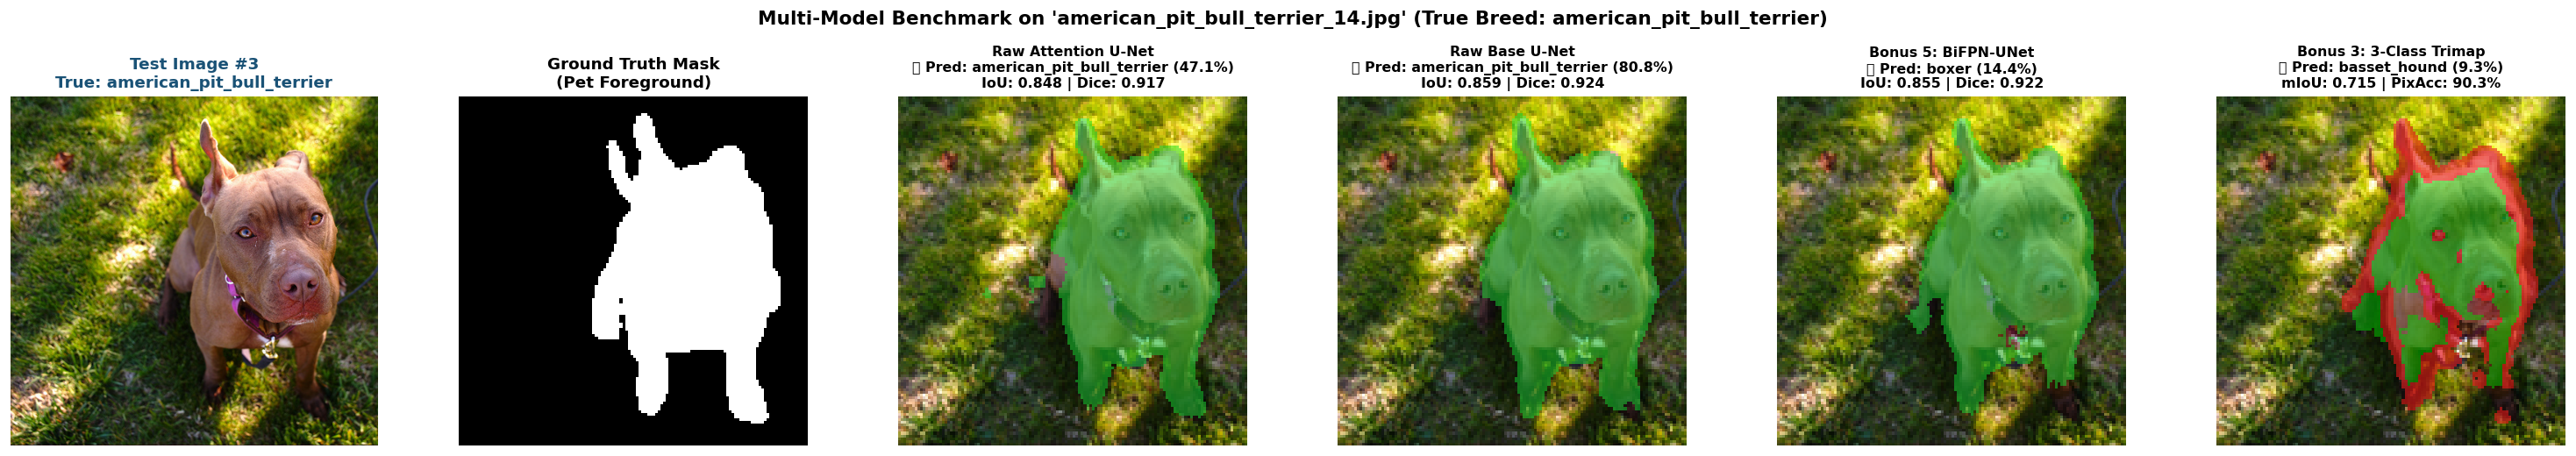

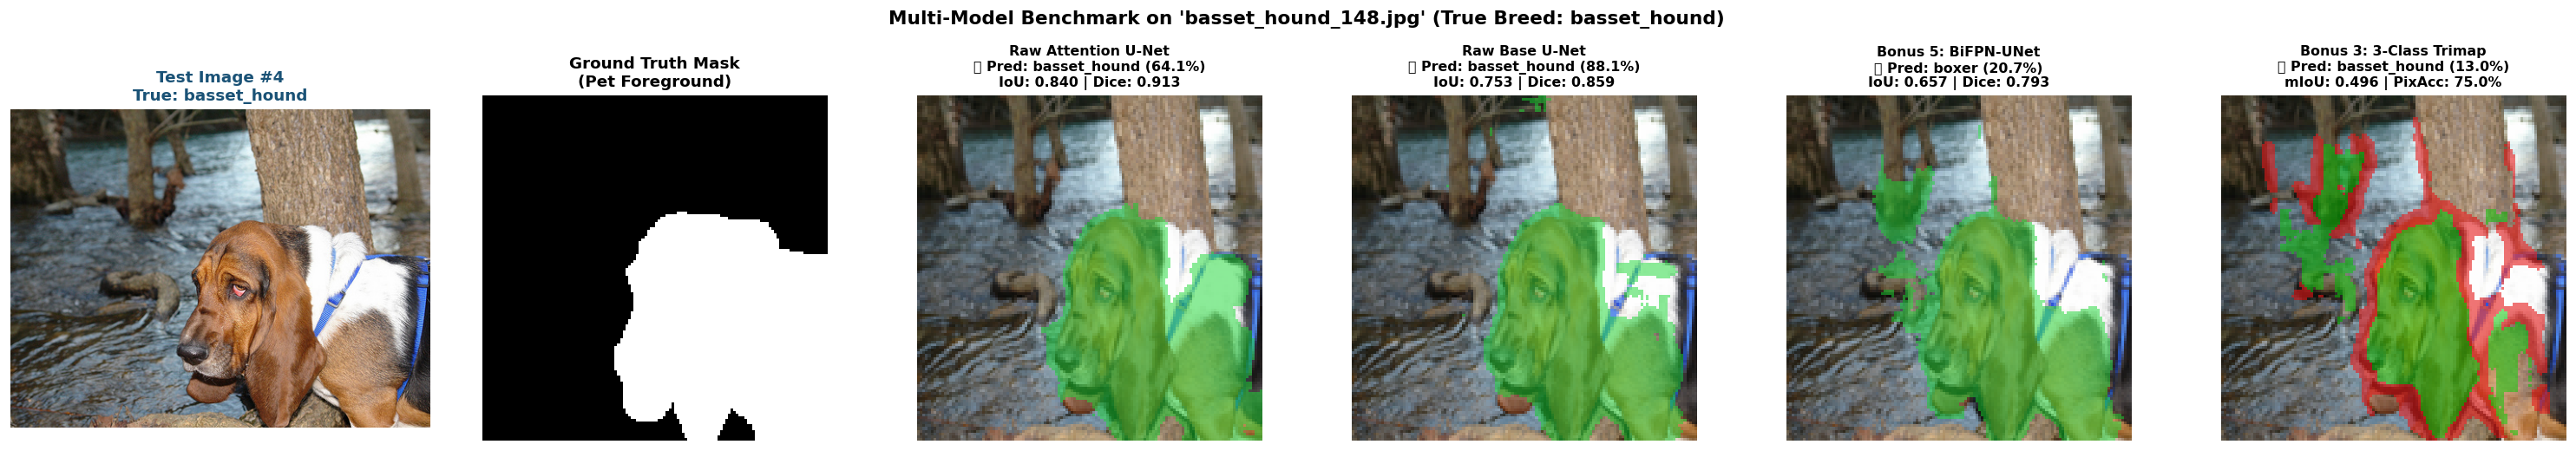

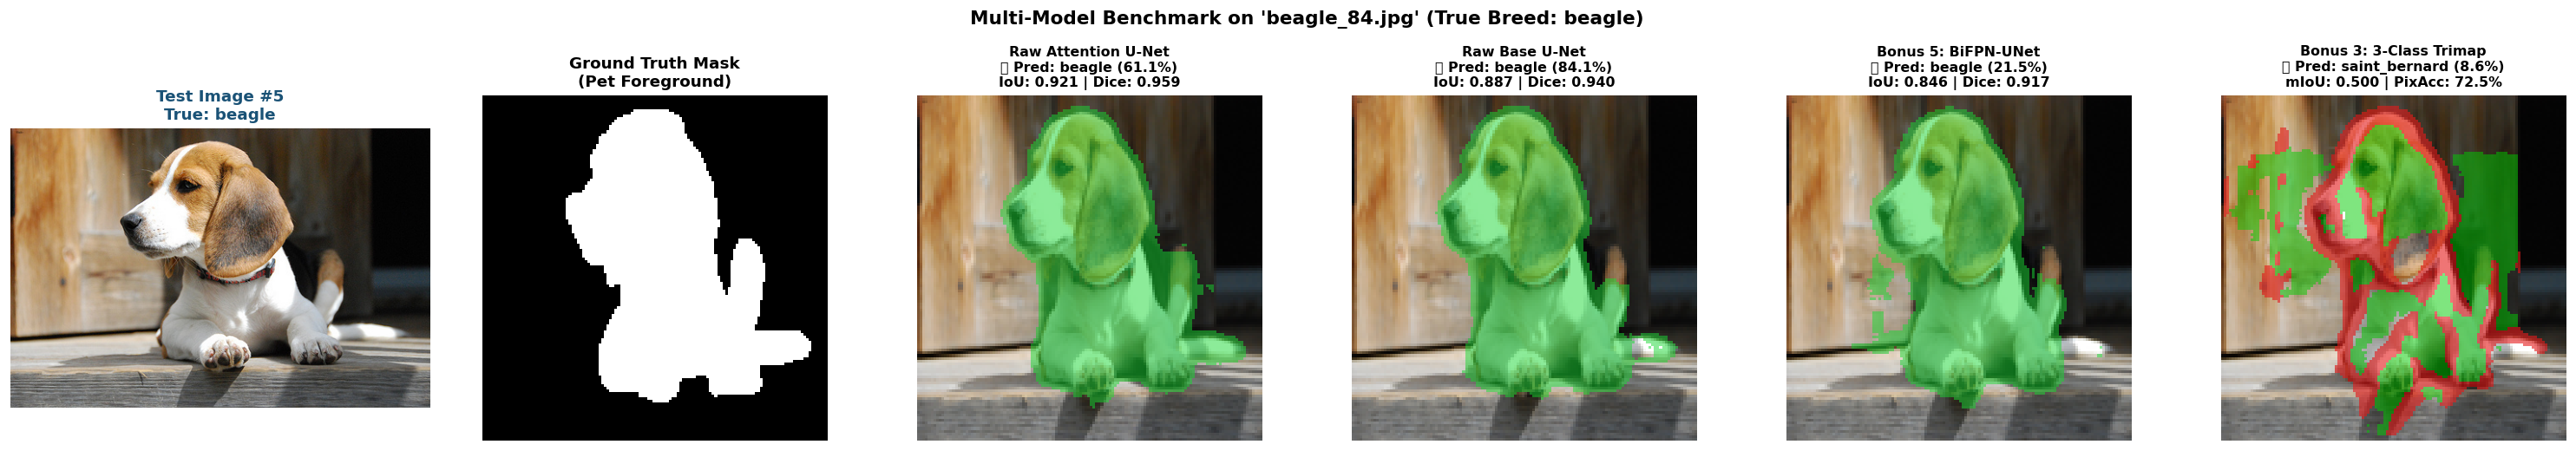

In [12]:
# Loop over and evaluate every single test image with full visual side-by-side & quantitative scoring
all_test_results = []

for img_idx, img_file in enumerate(test_image_files, 1):
    img_path = os.path.join(test_images_dir, img_file)
    base_name = os.path.splitext(img_file)[0]
    true_breed = '_'.join(base_name.split('_')[:-1])
    
    img_t, pil_img, _ = preprocess_image(img_path, img_size=128)
    gt_mask = load_ground_truth_mask(img_path, img_size=128)
    img_np = np.array(pil_img.resize((128, 128))) / 255.0

    n_models = len(models_to_compare)
    fig, axes = plt.subplots(1, n_models + 2, figsize=(4.2 * (n_models + 2), 4.2))

    # Subplot 0: Original Photo
    axes[0].imshow(pil_img)
    axes[0].set_title(f"Test Image #{img_idx}\nTrue: {true_breed}", fontsize=11, fontweight='bold', color='#1a5276')
    axes[0].axis('off')

    # Subplot 1: Ground Truth Mask
    if gt_mask is not None:
        gt_bin_viz = np.where(gt_mask == 2, 0, 1)
        axes[1].imshow(gt_bin_viz, cmap='gray')
        axes[1].set_title("Ground Truth Mask\n(Pet Foreground)", fontsize=11, fontweight='bold')
    else:
        axes[1].text(0.5, 0.5, 'No Mask Found', ha='center', va='center')
    axes[1].axis('off')

    # Subplots 2..N: Model predictions
    for idx, (name, (m, _, t_type)) in enumerate(models_to_compare.items(), start=2):
        ax = axes[idx]
        t0 = time.time()
        with torch.no_grad():
            seg, cls = m(img_t)
        dt = (time.time() - t0) * 1000.0

        p_cls = torch.softmax(cls, dim=1).squeeze().cpu().numpy()
        pred_b = idx_to_breed.get(np.argmax(p_cls), 'N/A')
        conf = np.max(p_cls) * 100.0

        if t_type == 'binary':
            p_seg = (torch.sigmoid(seg).squeeze().cpu().numpy() > 0.5).astype(np.uint8)
            overlay = img_np.copy()
            overlay[p_seg == 1] = overlay[p_seg == 1] * 0.5 + np.array([0.1, 0.85, 0.2]) * 0.5
            m_scores = calculate_metrics(p_seg, gt_mask, 'binary')
            iou_val = m_scores.get('Mean IoU', 0.0)
            dice_val = m_scores.get('Dice Coefficient', 0.0)
            pix_val = m_scores.get('Pixel Accuracy', 0.0)
            title_metric = f"IoU: {iou_val:.3f} | Dice: {dice_val:.3f}"
        else:
            p_seg = np.argmax(torch.softmax(seg, dim=1).squeeze().cpu().numpy(), axis=0)
            overlay = img_np.copy()
            overlay[p_seg == 0] = overlay[p_seg == 0] * 0.5 + np.array([0, 0.8, 0]) * 0.5
            overlay[p_seg == 2] = overlay[p_seg == 2] * 0.4 + np.array([0.9, 0.1, 0.1]) * 0.6
            m_scores = calculate_metrics(p_seg, gt_mask, '3class')
            iou_val = m_scores.get('Mean IoU (3-class)', 0.0)
            dice_val = m_scores.get('Pet IoU', 0.0)
            pix_val = m_scores.get('Pixel Accuracy', 0.0)
            title_metric = f"mIoU: {iou_val:.3f} | PixAcc: {pix_val*100:.1f}%"

        ax.imshow(overlay)
        is_corr = '✅' if pred_b.lower() == true_breed.lower() else '❌'
        ax.set_title(f"{name}\n{is_corr} Pred: {pred_b} ({conf:.1f}%)\n{title_metric}", fontsize=9.5, fontweight='bold')
        ax.axis('off')

        all_test_results.append({
            'Image Index': f"#{img_idx}",
            'Image File': img_file,
            'True Breed': true_breed,
            'Model': name,
            'Predicted Breed': pred_b,
            'Correct?': '✅ Correct' if pred_b.lower() == true_breed.lower() else '❌ Incorrect',
            'Confidence': f"{conf:.1f}%",
            'IoU': f"{iou_val:.3f}",
            'Dice': f"{dice_val:.3f}",
            'Pixel Acc': f"{pix_val*100:.1f}%",
            'Latency': f"{dt:.1f} ms"
        })

    plt.suptitle(f"Multi-Model Benchmark on '{img_file}' (True Breed: {true_breed})", fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


MASTER TEST SET EVALUATION SUMMARY (ALL 5 EXTERNAL TEST IMAGES)


Image Index,Image File,True Breed,Model,Predicted Breed,Correct?,Confidence,IoU,Dice,Pixel Acc,Latency
#1,Abyssinian_10.jpg,Abyssinian,Raw Attention U-Net,Abyssinian,✅ Correct,42.0%,0.657,0.793,86.4%,12.0 ms
#1,Abyssinian_10.jpg,Abyssinian,Raw Base U-Net,Maine_Coon,❌ Incorrect,60.1%,0.499,0.666,75.7%,6.0 ms
#1,Abyssinian_10.jpg,Abyssinian,Bonus 5: BiFPN-UNet,Abyssinian,✅ Correct,25.1%,0.539,0.701,78.4%,8.0 ms
#1,Abyssinian_10.jpg,Abyssinian,Bonus 3: 3-Class Trimap,Bombay,❌ Incorrect,28.0%,0.253,0.223,44.0%,5.0 ms
#2,american_bulldog_131.jpg,american_bulldog,Raw Attention U-Net,american_bulldog,✅ Correct,91.8%,0.913,0.955,96.5%,18.0 ms
#2,american_bulldog_131.jpg,american_bulldog,Raw Base U-Net,american_bulldog,✅ Correct,94.8%,0.925,0.961,97.0%,10.0 ms
#2,american_bulldog_131.jpg,american_bulldog,Bonus 5: BiFPN-UNet,pug,❌ Incorrect,28.0%,0.912,0.954,96.6%,9.0 ms
#2,american_bulldog_131.jpg,american_bulldog,Bonus 3: 3-Class Trimap,pug,❌ Incorrect,10.6%,0.530,0.495,76.5%,5.0 ms
#3,american_pit_bull_terrier_14.jpg,american_pit_bull_terrier,Raw Attention U-Net,american_pit_bull_terrier,✅ Correct,47.1%,0.848,0.917,95.3%,8.0 ms
#3,american_pit_bull_terrier_14.jpg,american_pit_bull_terrier,Raw Base U-Net,american_pit_bull_terrier,✅ Correct,80.8%,0.859,0.924,95.6%,5.0 ms



AVERAGE PERFORMANCE ACROSS ALL 5 TEST IMAGES BY MODEL


Model,Mean_IoU,Mean_Dice,Accuracy_Rate
Bonus 3: 3-Class Trimap,0.499,0.461,20%
Bonus 5: BiFPN-UNet,0.762,0.857,40%
Raw Attention U-Net,0.836,0.907,100%
Raw Base U-Net,0.785,0.870,80%


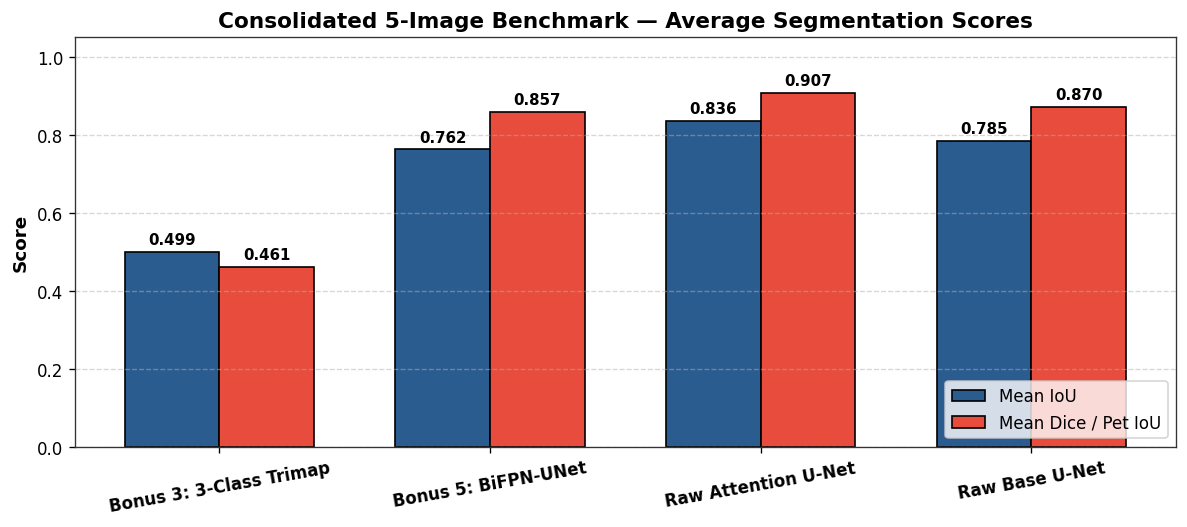

Universal Evaluation and 5-Image Benchmark complete — All models verified!


In [13]:
# ==============================================================================
# STEP 6: MASTER 5-IMAGE CONSOLIDATED BENCHMARK REPORT & SUMMARY BARS
# ==============================================================================
print('='*100)
print('MASTER TEST SET EVALUATION SUMMARY (ALL 5 EXTERNAL TEST IMAGES)')
print('='*100)

df_all = pd.DataFrame(all_test_results)
display(df_all.style.hide(axis='index'))

# Compute mean scores per model
print('\n' + '='*100)
print('AVERAGE PERFORMANCE ACROSS ALL 5 TEST IMAGES BY MODEL')
print('='*100)

df_stats = df_all.copy()
df_stats['IoU_num'] = df_stats['IoU'].astype(float)
df_stats['Dice_num'] = df_stats['Dice'].astype(float)

agg_summary = df_stats.groupby('Model').agg(
    Mean_IoU=('IoU_num', 'mean'),
    Mean_Dice=('Dice_num', 'mean'),
    Accuracy_Rate=('Correct?', lambda s: f"{(s == '✅ Correct').mean()*100:.0f}%")
).reset_index()

display(agg_summary.style.format({'Mean_IoU': '{:.3f}', 'Mean_Dice': '{:.3f}'}).hide(axis='index'))

# Summary Bar Chart across 5 Test Images
fig, ax = plt.subplots(figsize=(10, 4.5))
models_list = agg_summary['Model'].tolist()
x_pos = np.arange(len(models_list))
bar_w = 0.35

b1 = ax.bar(x_pos - bar_w/2, agg_summary['Mean_IoU'], width=bar_w, label='Mean IoU', color='#2b5c8f', edgecolor='black')
b2 = ax.bar(x_pos + bar_w/2, agg_summary['Mean_Dice'], width=bar_w, label='Mean Dice / Pet IoU', color='#e74c3c', edgecolor='black')

ax.set_xticks(x_pos)
ax.set_xticklabels(models_list, fontsize=10, fontweight='bold', rotation=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score', fontsize=11, fontweight='bold')
ax.set_title('Consolidated 5-Image Benchmark — Average Segmentation Scores', fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.3f}", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("Universal Evaluation and 5-Image Benchmark complete — All models verified!")
